# 02 · Demand forecasting experiment

Can a machine-learning model forecast next month's demand for each clinic and medicine better than simple rules, using only the reports that would have arrived by the forecast date?

The training, feature and inference code lives in `src/supplysignal/`; this notebook runs it and examines the results. Stock data is simulated (notebook 01).

In [1]:
import hashlib
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor

from supplysignal.features import Split, build_feature_panel, model_matrix, prepare_ledger, snapshot_features
from supplysignal.inference import predict
from supplysignal.train import _candidate_models, _fit_rows, run

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LEDGER = PROJECT / "data/processed/synthetic_lmis.csv"
MANIFEST = json.loads((PROJECT / "data/processed/manifest.json").read_text())
RUN = PROJECT / "artifacts/notebook-run"
RUN.mkdir(parents=True, exist_ok=True)
ARTIFACT = RUN / "demand_model.joblib"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TEAL, RED = "#237a80", "#c35c43"

## 1. Record the run

Package versions and SHA-256 hashes of the data and source code are saved with every run, so any result can be traced to the exact inputs that produced it.

In [2]:
tracked = [LEDGER, PROJECT / "data/processed/manifest.json", *sorted((PROJECT / "src/supplysignal").glob("*.py"))]
execution = {
    "executed_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "packages": {name: version(name) for name in ["numpy", "pandas", "scikit-learn", "lightgbm"]},
    "sha256": {str(path.relative_to(PROJECT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in tracked},
}
(RUN / "execution.json").write_text(json.dumps(execution, indent=2))
pd.Series({"python": execution["python"], **execution["packages"]}).to_frame("version")

,version
python,3.13.9
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
lightgbm,4.7.0


## 2. The dataset

One row per facility × medicine × month. Missing reports stay blank. The simulator's hidden truth columns (`truth_*`) are used only to score results, never as model inputs.

In [3]:
ledger = prepare_ledger(pd.read_csv(LEDGER))
assert len(ledger) == MANIFEST["operational_row_count"]
assert not ledger.duplicated(["facility_id", "commodity_id", "period"]).any()
assert ledger.loc[ledger.report_status.eq("missing"), "consumption"].isna().all()

print(f"{ledger.facility_id.nunique()} facilities · {ledger.commodity_id.nunique()} medicines · {ledger.period.nunique()} months · {len(ledger)} rows")
ledger.groupby(["commodity_id", "report_status"]).size().unstack(fill_value=0)

28 facilities · 3 medicines · 24 months · 2016 rows


report_status,missing,reported
commodity_id,,
magnesium_sulfate,38,634
misoprostol,32,640
oxytocin,33,639


## 3. Training labels

Consumption is capped by stock: in a month that ran out, dispensing understates real demand. The model therefore learns only from reported months with zero stockout days and positive closing stock.

In [4]:
reported = ledger.report_status.eq("reported")
labels = ledger.assign(
    reporting_delay_days=(ledger.submitted_at - (ledger.period + pd.offsets.MonthBegin(1))).dt.days,
    excluded_label=(ledger.stockout_days.gt(0) | ledger.closing_stock.eq(0)).where(reported),
)
labels.groupby("commodity_id").agg(
    median_delay_days=("reporting_delay_days", "median"),
    share_of_reports_excluded=("excluded_label", "mean"),
)

,median_delay_days,share_of_reports_excluded
commodity_id,,
magnesium_sulfate,8.0,0.031546
misoprostol,7.0,0.025
oxytocin,8.0,0.021909


## 4. Point-in-time features

For each forecast, features are built only from reports that had **arrived** by the forecast date: recent consumption, rolling averages, variability, report age, recent report counts, calendar month and medicine. The check below confirms no truth, label or stock column can enter the model.

In [5]:
panel = build_feature_panel(ledger, "2025-04-01")
vocabulary = sorted(ledger.commodity_id.unique())
sample = snapshot_features(ledger, "2026-06-01")
matrix = model_matrix(sample, vocabulary)

assert not any(term in column for column in matrix.columns for term in ("truth", "label", "stock"))
assert panel.as_of.eq(panel.target_period).all()
print("Model inputs:", ", ".join(matrix.columns))
sample[["facility_id", "commodity_id", "target_period", "last_consumption", "mean_3_consumption", "report_age_months"]].head()

Model inputs: month_sin, month_cos, last_consumption, mean_3_consumption, mean_6_consumption, std_3_consumption, report_age_months, visible_reports_last_3, visible_reports_last_6, commodity__magnesium_sulfate, commodity__misoprostol, commodity__oxytocin


,facility_id,commodity_id,target_period,last_consumption,mean_3_consumption,report_age_months
0,0eceb876-3124-426a-ada6-525073e86e21,magnesium_sulfate,2026-06-01,3.0,3.333333,2
1,0eceb876-3124-426a-ada6-525073e86e21,misoprostol,2026-06-01,12.0,11.000000,2
2,0eceb876-3124-426a-ada6-525073e86e21,oxytocin,2026-06-01,11.0,9.666667,3
3,23f5fcd1-3095-45ae-91d8-bbe0d89cb388,magnesium_sulfate,2026-06-01,4.0,4.666667,2
4,23f5fcd1-3095-45ae-91d8-bbe0d89cb388,misoprostol,2026-06-01,26.0,24.333333,2


## 5. Chronological split

All clinics share the same calendar boundaries, so no future month can leak into training: train on target months April 2025–February 2026, validate on March–May 2026, test on June–September 2026. Labels must also have been submitted before each cut-off.

In [6]:
split = Split()
panel["fold"] = "test"
panel.loc[panel.target_period.le(pd.Timestamp(split.train_end)), "fold"] = "train"
in_validation = panel.target_period.gt(pd.Timestamp(split.train_end)) & panel.target_period.le(pd.Timestamp(split.validation_end))
panel.loc[in_validation, "fold"] = "validation"

assert panel.loc[panel.fold.eq("train"), "target_period"].max() < panel.loc[panel.fold.eq("validation"), "target_period"].min()
assert panel.loc[panel.fold.eq("validation"), "target_period"].max() < panel.loc[panel.fold.eq("test"), "target_period"].min()
panel.groupby("fold").agg(
    rows=("facility_id", "size"),
    months=("target_period", "nunique"),
    usable_labels=("label_uncensored", "sum"),
).loc[["train", "validation", "test"]]

,rows,months,usable_labels
fold,,,
train,924,11,856
validation,252,3,233
test,336,4,301


## 6. Train and compare models

Two simple rules (last report, three-report mean) compete with two gradient-boosting models (scikit-learn and LightGBM, Poisson loss, fixed settings). The lowest **validation** error picks the model, which is then refit on train + validation and scored once on the test months. WAPE is total absolute error divided by total actual demand.

In [7]:
report = run(
    ledger_path=LEDGER,
    artifact_path=ARTIFACT,
    report_path=RUN / "training_report.json",
    predictions_path=RUN / "test_predictions.csv",
)
selected = report["selected_model"]
print("Selected on validation:", selected)
pd.DataFrame(report["validation_metrics"]).T.sort_values("mae")

Selected on validation: lightgbm


,n,mae,wape,bias_units
lightgbm,252.0,2.4376,0.1743,-0.1104
hist_gradient_boosting,252.0,2.4677,0.1764,-0.0017
mean_last_3_reports,252.0,2.4907,0.1781,-0.2209
last_report,252.0,3.1151,0.2227,-0.4802


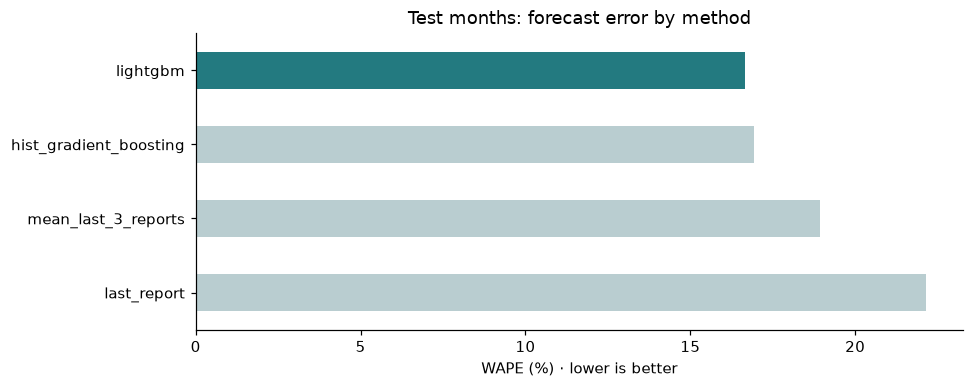

,n,mae,wape,bias_units
lightgbm,336.0,2.6712,0.1666,-0.3316
hist_gradient_boosting,336.0,2.7151,0.1693,-0.2306
mean_last_3_reports,336.0,3.0347,0.1893,-1.7133
last_report,336.0,3.5536,0.2216,-1.0893


,n,mae,wape,bias_units
magnesium_sulfate,112.0,1.1302,0.1642,-0.2433
misoprostol,112.0,3.9323,0.1571,-1.0130
oxytocin,112.0,2.9511,0.1823,0.2616


In [8]:
test_scores = pd.DataFrame(report["test_metrics"]).T.sort_values("wape")

fig, ax = plt.subplots(figsize=(9, 3.5))
(test_scores.wape * 100).sort_values(ascending=False).plot.barh(ax=ax, color=[TEAL if name == selected else "#b9cdd0" for name in test_scores.wape.sort_values(ascending=False).index])
ax.set(xlabel="WAPE (%) · lower is better", title="Test months: forecast error by method")
plt.show()

display(test_scores)
pd.DataFrame(report["selected_test_by_commodity"]).T

## 7. From forecast to alert

A forecast becomes useful when it triggers an action. Projecting each clinic's last reported stock forward with the forecast flags clinics that may run out. This step counts how many of those flags were real shortages.

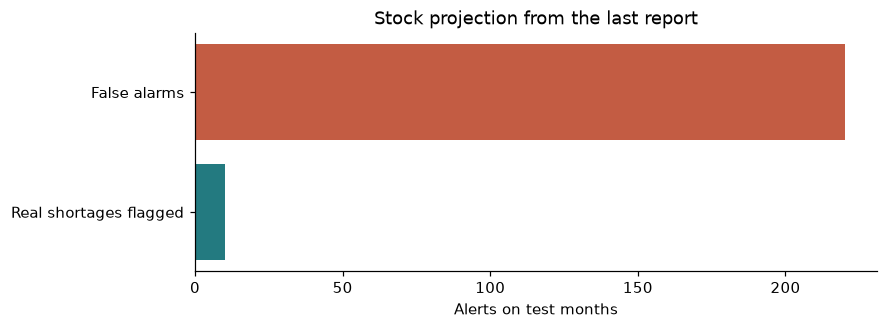

Real shortages flagged: 10 of 11  ·  false alarms: 220


In [9]:
alerts = report["selected_test_alert_metrics"]

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(["Real shortages flagged", "False alarms"], [alerts["true_positives"], alerts["false_positives"]], color=[TEAL, RED])
ax.set(xlabel="Alerts on test months", title="Stock projection from the last report")
plt.show()

print(f"Real shortages flagged: {alerts['true_positives']} of {alerts['actual_events_total']}  ·  false alarms: {alerts['false_positives']}")

Ten of the eleven real shortages are flagged, but with about twenty false alarms for each one. Notebook 03 shows the cause: the last report is stale and misses deliveries made since, which a quick count fixes.

## 8. Forecast for the demo date

The same feature builder produces October 2026 forecasts for every expected clinic and medicine, including any clinic without recent reports.

In [10]:
current = predict(LEDGER, ARTIFACT, "2026-10-01", "2026-10-04")
assert len(current) == 28 * 3 and current.model_name.nunique() == 1
current.sort_values("forecast_demand_units", ascending=False).head()

,facility_id,commodity_id,target_period,as_of,last_closing_stock,report_age_months,visible_reports_last_3,forecast_demand_units,model_name,model_provenance,requires_verification
43,7498b51f-ebf9-4b6d-8190-518bbe1eac9e,misoprostol,2026-10-01,2026-10-04,84.0,2,2,30.925175,lightgbm,simulated,True
40,6e6cfa53-734c-4466-a1ba-4df04c7cb799,misoprostol,2026-10-01,2026-10-04,32.0,2,2,30.489148,lightgbm,simulated,True
37,6e0a0381-a9ca-4b3d-868c-5ecc10068a0b,misoprostol,2026-10-01,2026-10-04,48.0,2,2,28.467011,lightgbm,simulated,True
79,f374e8ff-4bd5-4841-9d98-ad1a9fce25cd,misoprostol,2026-10-01,2026-10-04,68.0,2,2,28.341110,lightgbm,simulated,True
52,b2b4492a-2307-4cbf-bb90-5d4ebe744a5c,misoprostol,2026-10-01,2026-10-04,46.0,2,2,27.831073,lightgbm,simulated,True


## 9. Robustness: expanding windows and feature ablation

One split can be lucky. Here the model is refit at each of seven monthly forecast origins using only data available at that point ([time-series cross-validation](https://otexts.com/fpp3/tscv.html)), and compared with versions that drop calendar features or reporting features.

In [11]:
rows = []
for origin in pd.date_range("2026-03-01", "2026-09-01", freq="MS"):
    fit = _fit_rows(panel, origin - pd.offsets.MonthBegin(1), origin)
    target = panel.loc[panel.target_period.eq(origin)].copy()
    assert (fit.label_submitted_at <= origin).all() and fit.target_period.max() < origin

    x_fit = model_matrix(fit, vocabulary)
    x_target = model_matrix(target, vocabulary)
    feature_sets = {
        "full": list(x_fit.columns),
        "without_calendar": [c for c in x_fit if c not in ("month_sin", "month_cos")],
        "without_reporting": [c for c in x_fit if c not in ("report_age_months", "visible_reports_last_3", "visible_reports_last_6")],
    }
    forecasts = {"three_report_mean": target.mean_3_consumption.fillna(fit.label_consumption.median()).to_numpy()}
    for name, columns in feature_sets.items():
        model = _candidate_models()["lightgbm"]
        model.fit(x_fit[columns], fit.label_consumption)
        forecasts[name] = np.maximum(0, model.predict(x_target[columns]))

    actual = target.truth_demand.to_numpy()
    for name, values in forecasts.items():
        error = np.abs(values - actual).sum()
        rows.append({"origin": origin, "variant": name, "absolute_error_sum": error, "actual_sum": actual.sum(), "wape": error / actual.sum()})

rolling = pd.DataFrame(rows)
rolling.to_csv(RUN / "rolling_ablation.csv", index=False)
pooled = rolling.groupby("variant")[["absolute_error_sum", "actual_sum"]].sum()
pooled["wape"] = pooled.absolute_error_sum / pooled.actual_sum
pooled.sort_values("wape")

,absolute_error_sum,actual_sum,wape
variant,,,
full,1518.287396,8912.0,0.170364
without_reporting,1521.620763,8912.0,0.170738
without_calendar,1634.865427,8912.0,0.183445
three_report_mean,1647.333333,8912.0,0.184844


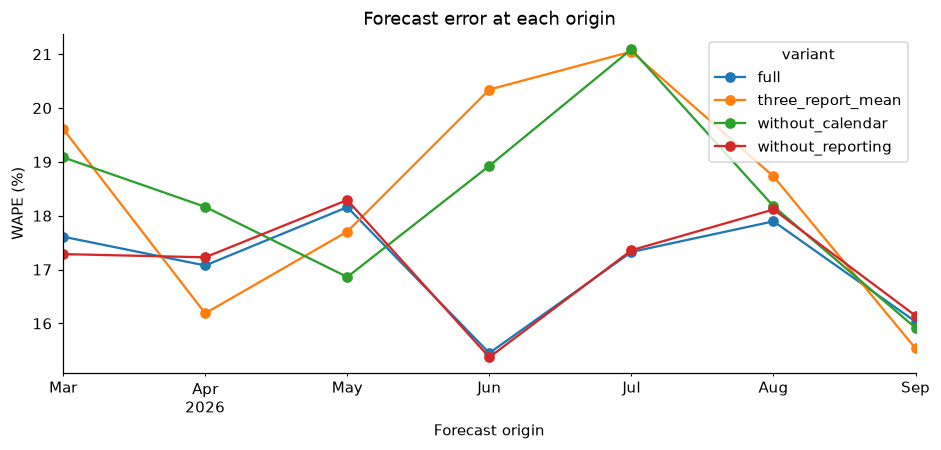

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
(rolling.pivot(index="origin", columns="variant", values="wape") * 100).plot(ax=ax, marker="o")
ax.set(ylabel="WAPE (%)", xlabel="Forecast origin", title="Forecast error at each origin")
plt.show()

## 10. Which features drive the forecast?

SHAP values split each forecast into the contribution of every feature. LightGBM computes them exactly for tree models, so no extra library is needed. The model is refit exactly as in step 6 (same data and settings).

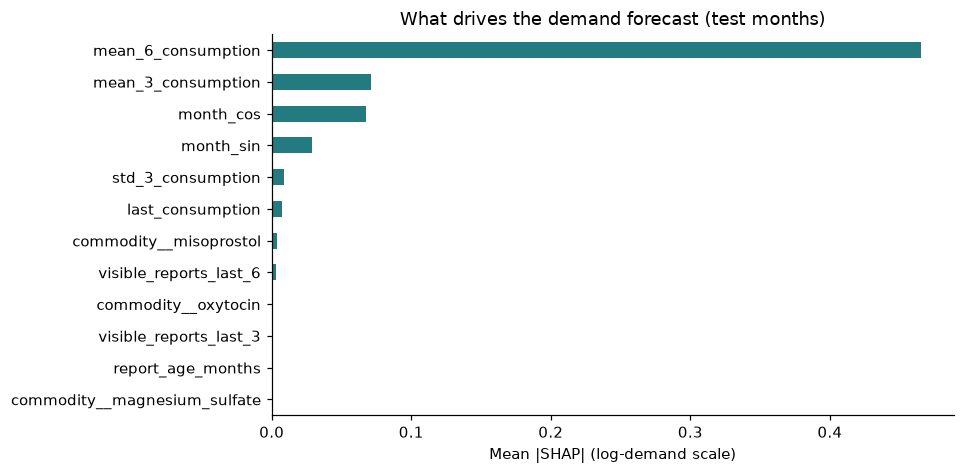

In [13]:
val_end = pd.Timestamp(split.validation_end)
refit_rows = _fit_rows(panel, val_end, val_end + pd.offsets.MonthBegin(1))
test_rows = panel[(panel.target_period > val_end) & (panel.target_period <= pd.Timestamp(split.test_end))].copy()
x_refit = model_matrix(refit_rows, vocabulary)
x_test = model_matrix(test_rows, vocabulary)

point_model = _candidate_models()["lightgbm"].fit(x_refit, refit_rows.label_consumption)
contributions = point_model.booster_.predict(x_test, pred_contrib=True)[:, :-1]
importance = pd.Series(np.abs(contributions).mean(axis=0), index=x_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
importance.plot.barh(ax=ax, color=TEAL)
ax.set(xlabel="Mean |SHAP| (log-demand scale)", title="What drives the demand forecast (test months)")
plt.show()

The six-report average consumption dominates, followed by the three-report average and calendar month (the seasonal rise). Report age adds almost nothing to the *demand* forecast: freshness matters for whether stock evidence is current, not for how much is used. In the app, officers get plain-language reasons ("Why it appeared") rather than SHAP plots.

## 11. Forecast uncertainty

A stock decision depends on the risk of running short, not just the expected demand. Quantile LightGBM models give a range: P10 (low) to P90 (high), which should contain about 80% of outcomes.

Raw quantile ranges are often too narrow, so they are **calibrated with split conformal prediction**: fit on the training months, measure how far the validation months fall outside the range, and widen the range by that amount. Test months are used only for the final check.

Calibration uses only labels submitted by the first test forecast date. Coverage is empirical on this simulated temporal test; serial dependence and demand shift mean that the nominal 80% level is not a field guarantee. These ranges are a notebook experiment, not used by the deployed worklist.

In [14]:
base_settings = _candidate_models()["lightgbm"].get_params()

def fit_quantiles(rows):
    x = model_matrix(rows, vocabulary)
    return {q: LGBMRegressor(**{**base_settings, "objective": "quantile", "alpha": q}).fit(x, rows.label_consumption) for q in (0.1, 0.5, 0.9)}

def predict_range(models, rows):
    x = model_matrix(rows, vocabulary)
    low, mid, high = np.sort(np.vstack([np.maximum(0, models[q].predict(x)) for q in (0.1, 0.5, 0.9)]), axis=0)
    return low, mid, high

train_end = pd.Timestamp(split.train_end)
train_rows = _fit_rows(panel, train_end, train_end + pd.offsets.MonthBegin(1))
calibration_deadline = val_end + pd.offsets.MonthBegin(1)
calibration_rows = _fit_rows(panel, val_end, calibration_deadline)
calibration_rows = calibration_rows[calibration_rows.target_period > train_end]
assert calibration_rows.label_submitted_at.le(calibration_deadline).all()
quantile_models = fit_quantiles(train_rows)

cal_low, _, cal_high = predict_range(quantile_models, calibration_rows)
observed = calibration_rows.label_consumption.to_numpy()
scores = np.maximum(cal_low - observed, observed - cal_high)
margin = np.quantile(scores, min(1, 0.8 * (1 + 1 / len(scores))), method="higher")

low, mid, high = predict_range(quantile_models, test_rows)
actual = test_rows.truth_demand.to_numpy()
coverage = pd.DataFrame({
    "range": ["Raw P10–P90", "Calibrated P10–P90"],
    "coverage": [np.mean((actual >= low) & (actual <= high)), np.mean((actual >= low - margin) & (actual <= high + margin))],
    "mean_width_units": [np.mean(high - low), np.mean(high - low + 2 * margin)],
}).set_index("range")
print(f"Calibration margin from {len(scores)} validation rows: ±{margin:.2f} units")
coverage.style.format({"coverage": "{:.1%}", "mean_width_units": "{:.1f}"})

Calibration margin from 150 validation rows: ±0.69 units


,coverage,mean_width_units
range,,
Raw P10–P90,63.7%,6.2
Calibrated P10–P90,78.0%,7.6


In [15]:
test_rows = test_rows.assign(p50=mid, p90_calibrated=high + margin, target_key=test_rows.target_period.dt.strftime("%Y-%m-%d"))
preds = pd.read_csv(RUN / "test_predictions.csv").merge(
    test_rows[["facility_id", "commodity_id", "target_key", "p50", "p90_calibrated"]],
    left_on=["facility_id", "commodity_id", "target_period"],
    right_on=["facility_id", "commodity_id", "target_key"],
    validate="one_to_one",
).merge(
    ledger.assign(period=ledger.period.dt.strftime("%Y-%m-%d"))[["facility_id", "commodity_id", "period", "opening_stock"]],
    left_on=["facility_id", "commodity_id", "target_period"],
    right_on=["facility_id", "commodity_id", "period"],
)
rows = preds.dropna(subset=["opening_stock", "last_closing_stock", "report_age_months"])
rows = rows[rows.report_age_months.le(2)]
real = rows.actual_stockout.astype(bool)

options = []
for information, stock, months in [("Last monthly report", rows.last_closing_stock, rows.report_age_months), ("Today's count", rows.opening_stock, 1)]:
    for estimate, demand in [("point forecast", rows.prediction_lightgbm), ("cautious P90", rows.p90_calibrated)]:
        flag = months * demand > stock
        options.append({"stock information": information, "demand estimate": estimate, "caught": int((flag & real).sum()), "false_alarms": int((flag & ~real).sum()), "missed": int((~flag & real).sum())})
pd.DataFrame(options).set_index(["stock information", "demand estimate"])

caught  false_alarms  missed
stock information   demand estimate                              
Last monthly report point forecast       10           201       0
                    cautious P90         10           247       0
Today's count       point forecast       10            49       0
                    cautious P90         10            98       0

Every option catches all real shortages on these rows. A more cautious forecast only adds false alarms; a fresh count removes most of them. Uncertainty is most useful for **how much** to request (a calibrated buffer), while **whom to call** depends on fresh stock information.

## 12. Results

In [16]:
chosen = report["test_metrics"][selected]
baseline = report["test_metrics"]["mean_last_3_reports"]
relative = (baseline["wape"] - chosen["wape"]) / baseline["wape"]

print(f"Selected model: {selected}")
print(f"Test WAPE: {chosen['wape']:.1%} vs {baseline['wape']:.1%} for the three-report mean ({relative:.0%} lower error)")
print(f"Mean bias: {chosen['bias_units']:+.2f} units")
print(f"Expanding-window WAPE: full {pooled.loc['full', 'wape']:.1%} · without calendar {pooled.loc['without_calendar', 'wape']:.1%} · without reporting {pooled.loc['without_reporting', 'wape']:.1%}")
print(f"P10–P90 coverage: {coverage.coverage.iloc[0]:.0%} raw → {coverage.coverage.iloc[1]:.0%} after conformal calibration (target 80%)")

Selected model: lightgbm
Test WAPE: 16.7% vs 18.9% for the three-report mean (12% lower error)
Mean bias: -0.33 units
Expanding-window WAPE: full 17.0% · without calendar 18.3% · without reporting 17.1%
P10–P90 coverage: 64% raw → 78% after conformal calibration (target 80%)


## What this means

- **LightGBM is the most accurate forecaster**, cutting test error by about 12% relative to the three-report average. Pooled over seven forecast origins it stays ahead (17.0% vs 18.5%), though not in every single month.
- **A good forecast is not enough on its own.** Projected from stale stock, it still raises many false alarms. That points to fresh stock information, not a bigger model, as the next lever (notebook 03).
- **Calibrated uncertainty.** Conformal calibration turns over-confident quantile ranges into ranges that hold their promised 80% coverage. That's the right basis for sizing buffers and transfer quantities.
- **The selected model is versioned and packaged** in notebook 04.